### Lấy mẫu ngẫu nhiên từ dataset `loan.csv`

Dưới đây là list các cách phổ biến dùng để lấy mẫu dữ liệu từ cơ bản cho các dataset nhỏ, đến các công cụ thường được các Data Scientist dùng khi đọc dataset cực lớn.

1. `pd.read_csv()`      đọc toàn bộ dữ liệu vào RAM, phù hợp với dataset nhỏ hoặc vừa.
2. `df.sample()`        dùng để lấy mẫu ngẫu nhiên khi đã có `df`, thường được dùng với `pd.read_csv()`.
3. `chunksize`          tiết kiệm RAM bằng cách đọc dữ liệu theo từng phần (chunk).
4. `Reservoir Sampling` lấy mẫu ngẫu nhiên chuẩn trên các dataset rất lớn mà không cần lưu toàn bộ dữ liệu trong bộ nhớ.
5. `DuckDB / Polars`    công cụ xử lý dữ liệu lớn với hiệu năng cao.
6. `Spark`              xử lý dữ liệu cực lớn trên hệ thống phân tán.

Trong bài này vì dataset `loan.csv` có kích thước khoảng 1gb nên dùng `pd.read_csv` và `df.sample` là vừa đủ.

In [ ]:
import pandas as pd

df = pd.read_csv("../../loan.csv")
df_sample = df.sample(n=1000, random_state=2412)

### EDA - Exploratory Data Analysis

1. Xem dữ liệu (`head()`, `tail()`)
2. Xem kích thước dataset (`shape`)
3. Xem kiểu dữ liệu (`info()`)
4. Thống kê tỷ lệ missing
5. Xem các cột hằng số hoặc có quá ít giá trị unique
6. Phân loại cột thành `numerical` và `categorical`
7. Xác định biến mục tiêu (target)
8. Chọn các cột quan trọng để phân tích
9. Quan sát biểu đồ:
    - Histogram
    - Boxplot (đối với numerical)
10. Phân tích các cột `categorical`

### Data Preprocessing
11. Xử lý dữ liệu thiếu (missing values)
12. Xử lý outlier (`log1p`)



##### 1. `Xem dữ liệu`

In [ ]:
display(df_sample.head())
display(df_sample.tail())

##### 2. `Xem kích thước`

In [ ]:
df_sample.shape

##### 3. `Xem kiểu dữ liệu`

In [ ]:
df_sample.info()

##### 4. ` Thống kê missing values`

In [ ]:
missing_stats = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": round(df.isna().mean() * 100, 2)
})

missing_stats = missing_stats.sort_values(
    by="missing_pct",
    ascending=False
)

missing_stats.head(20)

#### Vì số cột có tỉ lệ missing cao (>90%) tương đối nhiều nên xóa hết
Xem các cột có missing value >70%

In [ ]:
cols_to_drop = missing_stats[
    missing_stats["missing_pct"] > 70
]

print(f"Số cột sẽ bị xóa: {len(cols_to_drop)}")
display(cols_to_drop)

Xóa các cột đó

In [ ]:
df_sample=df_sample.drop(columns=cols_to_drop.index)

#### 5. ` Thống kê unique `
- Thống kê số lượng giá trị unique của từng cột.
- Loại bỏ các cột hằng số (unique = 1).
- Xem xét các cột có số lượng unique rất thấp hoặc quá cao (ID, URL, ...) tuy nhiên hông nên tùy ý xóa các cột unique rất thấp hoặc quá cao nếu chưa biết rõ nghiệp vụ, do đó trong bài này chỉ xóa các cột hằng số.

In [ ]:
unique_stats = pd.DataFrame({
    "unique_count": df_sample.nunique()
})

unique_stats.sort_values(
    by="unique_count"
).head(20)

In [ ]:
constant_cols = unique_stats[
    unique_stats["unique_count"] == 1
].index

constant_cols

In [ ]:
df_sample = df_sample.drop(columns=constant_cols)

##### 6. Phân loại cột thành `numerical` và `categorical`

In [ ]:
num_cols = df_sample.select_dtypes(include="number").columns
cat_cols = df_sample.select_dtypes(exclude="number").columns

print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")

Xem danh sách cột num & cột cat để rà lại và chỉnh sửa các kiểu dữ liệu

In [ ]:
list(num_cols)

In [ ]:
list(cat_cols)

Phát hiện các cột:
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "last_credit_pull_d"
là cột date chứ kh phải cat, nên chúng ta sẽ chuyển đổi

In [ ]:
date_cols = [
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "last_credit_pull_d"
]

for col in date_cols:
    df_sample[col] = pd.to_datetime(
        df_sample[col],
        errors="coerce"
    )

##### 7. Xác định biến mục tiêu (target)
Cần trả lời:
- Lãi suất nằm trong khoảng nào?
- Có bị lệch không?
- Có outlier không?

In [ ]:
target = "int_rate"
df_sample["int_rate"].describe()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_sample["int_rate"])

plt.show()

- Lãi suất khoản vay dao động từ 5.31% đến 30.99%.
- 50% khoản vay có lãi suất nằm trong khoảng từ 9.70% đến 15.99%.
- Phân phối có xu hướng lệch phải, cho thấy phần lớn khách hàng có lãi suất trung bình và chỉ một số ít khách hàng có lãi suất rất cao.
- Theo quy tắc IQR, tồn tại một số giá trị outlier ở phía trên. Tuy nhiên các giá trị này vẫn nằm trong phạm vi hợp lý của lãi suất vay.
- Không suất hiện các lỗi nhập liệu như 300%, -999%
---

##### 8. Chọn các feature quan trọng dựa trên
1. Correlation cho các cột số với biến mục tiêu

2. Chọn thêm các cột categorical có ý nghĩa nghiệp vụ: term, grade, sub_grade, verifcation_status, home_ownership

In [ ]:
corr_with_target = (
    df_sample[num_cols]
    .corr()["int_rate"]
    .abs()
    .sort_values(ascending=False)
)

corr_with_target.head(20)

Các numerical feature được chọn gồm:
- `total_rec_int`
- `all_util`
- `bc_open_to_buy`
- `percent_bc_gt_75`
- `bc_util`

Đây là các feature có độ tương quan tương đối cao với biến mục tiêu `int_rate`.

Ngoài ra, một số feature cũng được lựa chọn dựa trên ý nghĩa nghiệp vụ:

- `annual_inc`
- `loan_amnt`
- `dti`

Kết hợp với các categorical feature:

- `term`
- `grade`
- `sub_grade`
- `verification_status`
- `home_ownership`

Loại bỏ các cột mặc dù có độ tương quan cao nhưng có khả năng gây data leakage:
`total_rec_int`.

In [ ]:
# Numerical features
important_num_cols = [
    "all_util",
    "bc_open_to_buy",
    "percent_bc_gt_75",
    "bc_util",
    "annual_inc",
    "loan_amnt",
    "dti"
]
# Categorical features
important_cat_cols = [
    "term",
    "grade",
    "sub_grade",
    "verification_status",
    "home_ownership"
]
eda_cols = important_num_cols + important_cat_cols + [target]

df_eda = df_sample[eda_cols]

df_eda.head()

##### 9. Quan sát biểu đồ:
    - Histogram

In [ ]:
for col in important_num_cols:
    sns.histplot(df_eda[col], kde=True)
    plt.title(col)
    plt.show()

    - Boxplot (đối với numerical)

In [ ]:
for col in important_num_cols:
    sns.boxplot(x=df_eda[col])
    plt.title(col)
    plt.show()

##### 10. Phân tích các cột `categorical`

In [ ]:
for col in important_cat_cols:
    display(
        df_eda.groupby(col)["int_rate"]
              .mean()
              .sort_values()
    )

##### 11. Xử lý missing value

In [ ]:
missing_stats = pd.DataFrame({
    "missing_count": df_eda.isna().sum(),
    "missing_pct": round(df_eda.isna().mean() * 100, 2)
})

missing_stats = missing_stats.sort_values(
    by="missing_pct",
    ascending=False
)

display(missing_stats)

Cột all_util thiếu khá nhiều, quan sát histogram và boxplot thấy được cột này có phân phối gần chuẩn và ít outlier, median cũng gần bằng mean nên dùng mean hay median đều hợp lý

Cột bc_open_to_buy, lệch phải nặng nên kh dùng mean

Cột percent_bc_gt_75 và bc_util, không chuẩn => dùng median cho an toàn

In [ ]:
# all_util
df_eda["all_util"] = (
    df_eda["all_util"]
    .fillna(df_eda["all_util"].mean())
)

# các cột lệch hoặc có outlier
for col in [
    "bc_open_to_buy",
    "percent_bc_gt_75",
    "bc_util",
    "dti"
]:
    df_eda[col] = (
        df_eda[col]
        .fillna(df_eda[col].median())
    )

##### 12. Xử lý outlier

In [57]:
for col in important_num_cols:
    Q1 = df_eda[col].quantile(0.25)
    Q3 = df_eda[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_eda[
        (df_eda[col] < lower) |
        (df_eda[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} outliers "
        f"({round(len(outliers)/len(df_eda)*100,2)}%)"
    )

all_util: 211 outliers (21.1%)
bc_open_to_buy: 48 outliers (4.8%)
percent_bc_gt_75: 0 outliers (0.0%)
bc_util: 0 outliers (0.0%)
annual_inc: 23 outliers (2.3%)
loan_amnt: 14 outliers (1.4%)
dti: 10 outliers (1.0%)


Cột `all_util` có tỷ lệ outlier khá cao (21.1%) theo phương pháp IQR. Tuy nhiên khi quan sát histogram và boxplot, có thể thấy dữ liệu vẫn phân bố tương đối tự nhiên và không xuất hiện các giá trị bất thường về mặt nghiệp vụ. Do đó các outlier của cột này sẽ được giữ lại.

Các feature annual_inc và bc_open_to_buy có phân phối lệch phải và chứa nhiều giá trị lớn.

Sử dụng log transformation để giảm độ lệch của phân phối, giảm ảnh hưởng của outlier và giúp dữ liệu ổn định hơn cho mô hình.

Các cột `loan_amnt`, `dti`, `bc_util` và `percent_bc_gt_75` có số lượng outlier thấp hoặc không đáng kể, vì vậy không cần xử lý thêm ở bước này. 

In [54]:
import numpy as np

df_eda["bc_open_to_buy"] = np.log1p(
    df_eda["bc_open_to_buy"]
)

In [55]:
df_eda["annual_inc"] = np.log1p(
    df_eda["annual_inc"]
)

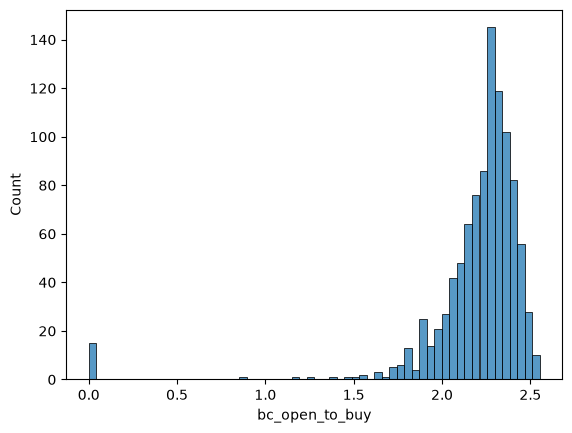

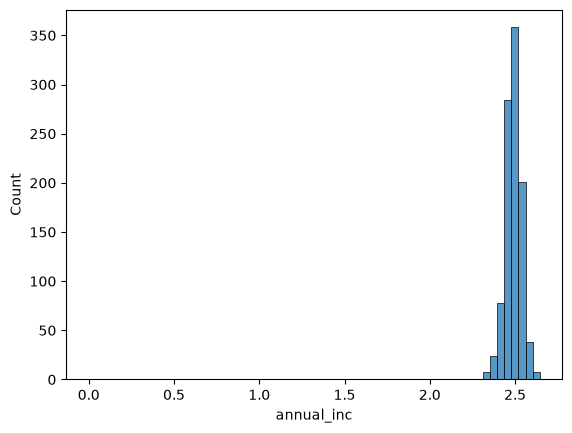

In [56]:
sns.histplot(df_eda["bc_open_to_buy"])
plt.show()

sns.histplot(df_eda["annual_inc"])
plt.show()